# 06 — Final Model Comparison & Selection
**Project:** Hotel Booking Cancellation Prediction (IT3051 – Fundamentals of Data Mining)

This notebook brings together the four models built in `notebooks/05_modeling/`:

| Notebook | Model | Saved pipeline |
|---|---|---|
| `logistic_regression.ipynb` | Logistic Regression (tuned, `class_weight='balanced'`) | `models/logistic_regression/pipeline.joblib` |
| `decision_tree.ipynb` | Decision Tree (tuned, GridSearchCV) | `models/decision_tree_tuned.joblib` |
| `random_forest.ipynb` | Random Forest | `models/random_forest_tuned.joblib` if it exists, else `models/baseline_random_forest.joblib` |
| `xgboost.ipynb` | XGBoost (tuned, `scale_pos_weight`) | `models/xgboost_model.joblib` |

**Fair comparison rules**
- All four saved pipelines are re-evaluated here on the **same shared test set** (`data/splits/X_test.csv`, 17,445 rows).
- All four use the **same 0.5 threshold**.
- The test set is used only for evaluation; nothing is refitted.

**Outputs**
- Comparison table and charts.
- Final model selection with justification.
- `models/final_model.joblib` and `models/final_model_info.json` for the backend (Stage 9).

## 1. Setup and project paths

In [1]:
import os, sys, json, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# Mount Google Drive when running in Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# XGBoost must be installed to load the saved XGBoost pipeline
try:
    import xgboost
except ImportError:
    %pip install -q xgboost
    import xgboost

import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

# ---------------------------------------------------------------
# PROJECT PATHS (same folder used by every 05_modeling notebook)
# Drive: Shared with me > hotel-booking-cancellation
# If the folder is only in "Shared with me", right-click it in Drive
# and choose Organise > Add shortcut > My Drive so Colab can see it.
# ---------------------------------------------------------------
ROOT = Path(os.environ.get('HOTEL_BOOKING_ROOT',
                           '/content/drive/MyDrive/hotel-booking-cancellation'))

SPLIT_DIR   = ROOT / 'data' / 'splits'
MODEL_DIR   = ROOT / 'models'
RESULTS_DIR = ROOT / 'results'
FINAL_DIR   = RESULTS_DIR / 'final_comparison'
FINAL_DIR.mkdir(parents=True, exist_ok=True)

for p in [ROOT, SPLIT_DIR, MODEL_DIR]:
    print(('OK      ' if p.exists() else 'MISSING ') + str(p))
assert SPLIT_DIR.exists(), 'Project folder not found — check ROOT / add the Drive shortcut.'

# If the LR pipeline was built with helpers from src/, make them importable
for extra in [ROOT, ROOT / 'src']:
    if extra.exists() and str(extra) not in sys.path:
        sys.path.insert(0, str(extra))

THRESHOLD = 0.5
RANDOM_STATE = 42
print(f'\nscikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | pandas {pd.__version__}')

Mounted at /content/drive
OK      /content/drive/MyDrive/hotel-booking-cancellation
OK      /content/drive/MyDrive/hotel-booking-cancellation/data/splits
OK      /content/drive/MyDrive/hotel-booking-cancellation/models

scikit-learn 1.6.1 | xgboost 3.4.1 | pandas 2.2.3


## 2. Load the shared train/test splits

In [2]:
X_train = pd.read_csv(SPLIT_DIR / 'X_train.csv', dtype={'agent': str})
X_test  = pd.read_csv(SPLIT_DIR / 'X_test.csv',  dtype={'agent': str})
y_train = pd.read_csv(SPLIT_DIR / 'y_train.csv')['is_canceled']
y_test  = pd.read_csv(SPLIT_DIR / 'y_test.csv')['is_canceled']

config_path = MODEL_DIR / 'preprocessing_config.json'
config = json.loads(config_path.read_text()) if config_path.exists() else {}
if config.get('sklearn_version') and config['sklearn_version'] != sklearn.__version__:
    print(f"NOTE: models were built with scikit-learn {config['sklearn_version']}, "
          f"this runtime has {sklearn.__version__}. If loading fails, run "
          f"%pip install scikit-learn=={config['sklearn_version']} and restart.")

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print(f'Cancellation rate — train: {y_train.mean():.2%} | test: {y_test.mean():.2%}')

X_train: (69777, 28) | X_test: (17445, 28)
Cancellation rate — train: 27.53% | test: 27.53%


## 3. Load the four final pipelines
Each `.joblib` file contains the **fitted preprocessing + model**, so raw `X_test` goes straight in.

If a file is not found at its expected path, the notebook searches `models/` for it. If a model still cannot be loaded, the numbers reported in its own notebook are used instead (marked `source = reported`).

In [3]:
CANDIDATES = {
    'Logistic Regression': ['logistic_regression/pipeline.joblib', '**/logistic_regression*/pipeline.joblib',
                            '**/logistic_regression*.joblib'],
    'Decision Tree':       ['decision_tree_tuned.joblib', '**/decision_tree*tuned*.joblib'],
    'Random Forest':       ['random_forest_tuned.joblib', '**/random_forest*tuned*.joblib',
                            'baseline_random_forest.joblib', '**/*random_forest*.joblib'],
    'XGBoost':             ['xgboost_model.joblib', '**/xgboost*.joblib'],
}

def find_model(patterns):
    for pat in patterns:
        hits = sorted(MODEL_DIR.glob(pat))
        if hits:
            return hits[0]
    return None

models, model_paths = {}, {}
for name, patterns in CANDIDATES.items():
    path = find_model(patterns)
    if path is None:
        print(f'NOT FOUND  {name}')
        continue
    try:
        models[name] = joblib.load(path)
        model_paths[name] = path
        print(f'LOADED     {name:20s} <- {path.relative_to(ROOT)}')
    except Exception as e:
        print(f'LOAD ERROR {name}: {type(e).__name__}: {e}')

RF_VERSION = 'tuned' if 'Random Forest' in model_paths and 'tuned' in model_paths['Random Forest'].name else 'baseline'
print('\nRandom Forest version used:', RF_VERSION)

NOT FOUND  Logistic Regression
LOADED     Decision Tree        <- models/decision_tree_tuned.joblib
LOADED     Random Forest        <- models/baseline_random_forest.joblib
LOADED     XGBoost              <- models/xgboost_model.joblib

Random Forest version used: baseline


### Results reported in each model notebook (fallback + cross-check)
These are copied from the outputs of the four notebooks. They are used only if a pipeline cannot be loaded, and to confirm that the re-evaluation matches the original runs.

In [4]:
REPORTED = {
    'Logistic Regression': dict(Accuracy=0.7678, Precision=0.5529, Recall=0.8178, **{'F1-score': 0.6598}, **{'ROC-AUC': 0.8601},
                                tn=9468, fp=3175, fn=875, tp=3927),
    'Decision Tree':       dict(Accuracy=0.8313, Precision=0.7023, Recall=0.6720, **{'F1-score': 0.6868}, **{'ROC-AUC': 0.8839},
                                tn=11275, fp=1368, fn=1575, tp=3227),
    'Random Forest':       dict(Accuracy=0.8500, Precision=0.7680, Recall=0.6522, **{'F1-score': 0.7054}, **{'ROC-AUC': 0.9110},
                                tn=11697, fp=946, fn=1670, tp=3132),
    'XGBoost':             dict(Accuracy=0.8276, Precision=0.6371, Recall=0.8680, **{'F1-score': 0.7348}, **{'ROC-AUC': 0.9202},
                                tn=10269, fp=2374, fn=634, tp=4168),
}
METRICS = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']

## 4. Evaluate all four models on the same test set

In [5]:
probs, preds, rows = {}, {}, []

for name in CANDIDATES:
    if name in models:
        p = models[name].predict_proba(X_test)[:, 1]
        yhat = (p >= THRESHOLD).astype(int)
        probs[name], preds[name] = p, yhat
        tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
        rows.append({'Model': name,
                     'Accuracy': accuracy_score(y_test, yhat),
                     'Precision': precision_score(y_test, yhat),
                     'Recall': recall_score(y_test, yhat),
                     'F1-score': f1_score(y_test, yhat),
                     'ROC-AUC': roc_auc_score(y_test, p),
                     'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp, 'source': 'evaluated'})
    else:
        rows.append({'Model': name, **REPORTED[name], 'source': 'reported'})

results = pd.DataFrame(rows).set_index('Model')
display(results[METRICS + ['source']].round(4)
        .style.highlight_max(subset=METRICS, color='#c6efce').format(precision=4, subset=METRICS))

# Cross-check against the numbers in each model notebook
check = (results[METRICS] - pd.DataFrame(REPORTED).T[METRICS]).abs().max(axis=1)
for name, diff in check.items():
    flag = 'matches notebook' if diff < 0.005 else f'differs from notebook by up to {diff:.3f} (model was retrained/changed?)'
    print(f'{name:20s}: {flag}')

,Accuracy,Precision,Recall,F1-score,ROC-AUC,source
Model,,,,,,
Logistic Regression,0.7678,0.5529,0.8178,0.6598,0.8601,reported
Decision Tree,0.8306,0.6973,0.6793,0.6882,0.8839,evaluated
Random Forest,0.8500,0.7668,0.6541,0.7060,0.9110,evaluated
XGBoost,0.8276,0.6371,0.8680,0.7348,0.9202,evaluated


Logistic Regression : matches notebook
Decision Tree       : differs from notebook by up to 0.007 (model was retrained/changed?)
Random Forest       : matches notebook
XGBoost             : matches notebook


## 5. Visual comparison of the metrics

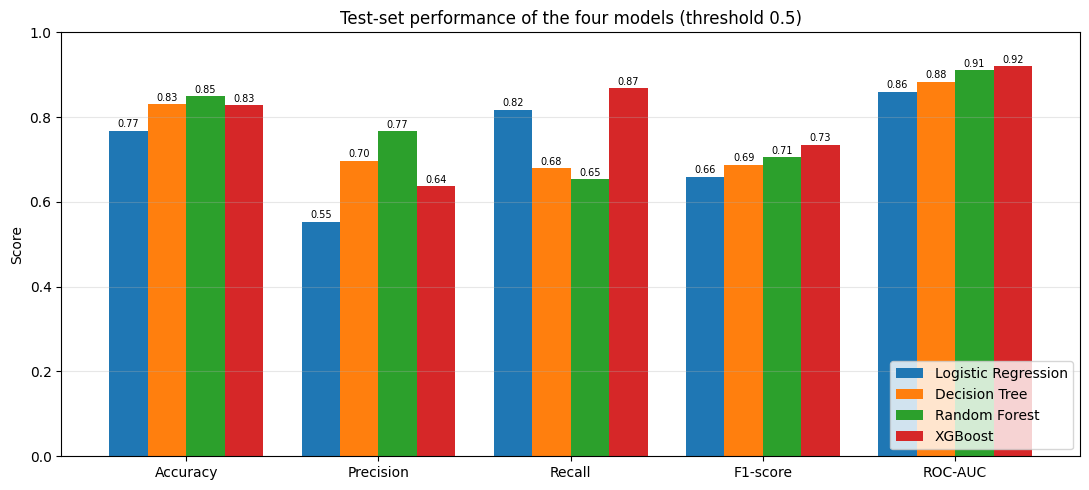

In [6]:
ax = results[METRICS].T.plot.bar(figsize=(11, 5), width=0.8, rot=0)
ax.set_ylim(0, 1); ax.set_ylabel('Score'); ax.set_title('Test-set performance of the four models (threshold 0.5)')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7, padding=1)
plt.tight_layout(); plt.savefig(FINAL_DIR / 'metric_comparison.png', dpi=150); plt.show()

## 6. ROC curves (threshold-independent comparison)

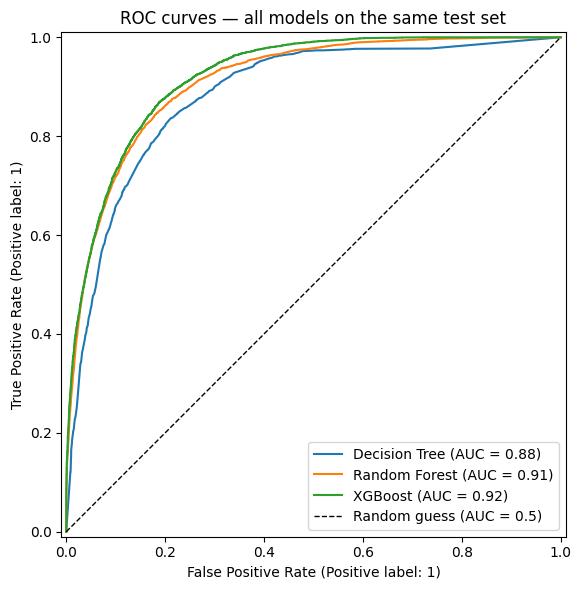

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, p in probs.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess (AUC = 0.5)')
ax.set_title('ROC curves — all models on the same test set'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FINAL_DIR / 'roc_curves.png', dpi=150); plt.show()

## 7. Confusion matrices and what they mean for the hotel
- **False negative (missed cancellation):** the room unexpectedly stays empty, so revenue is lost.
- **False positive (false alarm):** a guest is flagged as likely to cancel but arrives. The cost is low if the action is just a reminder or deposit request, but high if the hotel overbooks.

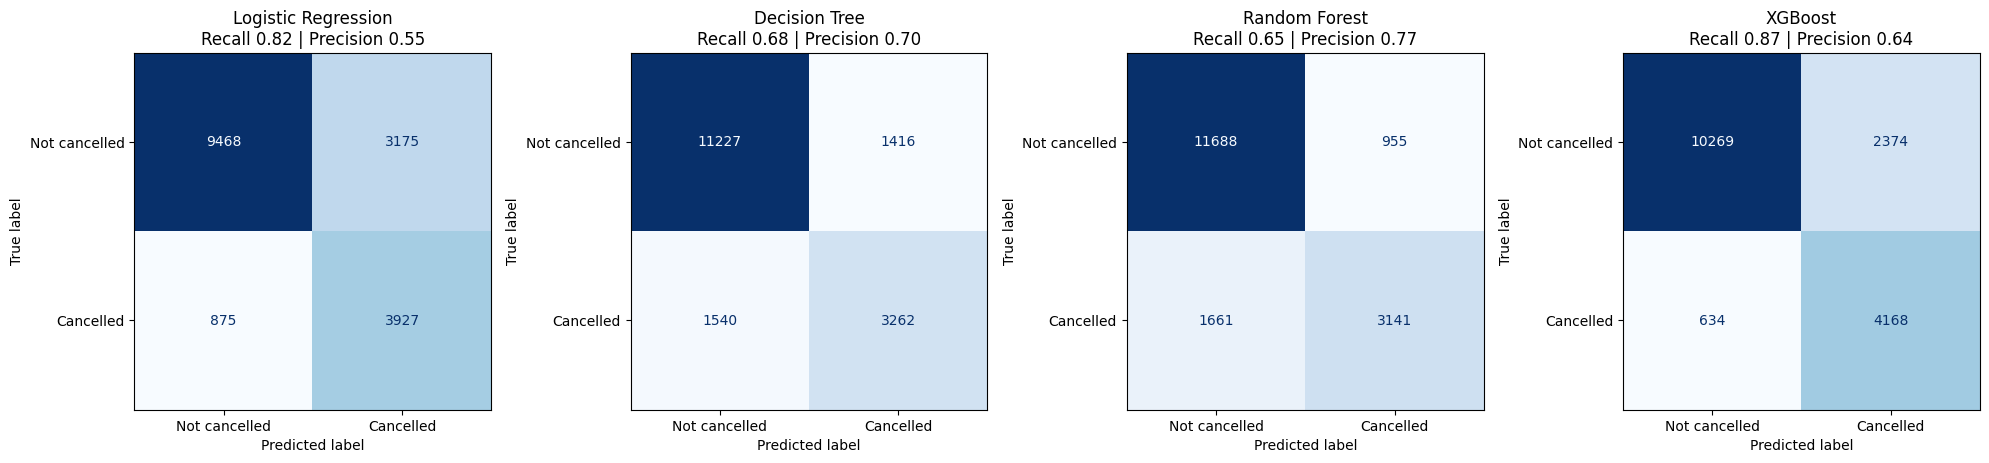

Test set: 17,445 bookings, of which 4,802 were actually cancelled


,Cancellations caught,Cancellations missed,False alarms,% of cancellations caught,"Missed per 1,000 bookings","False alarms per 1,000 bookings"
Model,,,,,,
Logistic Regression,3927,875,3175,81.8,50.2,182.0
Decision Tree,3262,1540,1416,67.9,88.3,81.2
Random Forest,3141,1661,955,65.4,95.2,54.7
XGBoost,4168,634,2374,86.8,36.3,136.1


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (name, r) in zip(axes, results.iterrows()):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=int)
    ConfusionMatrixDisplay(cm, display_labels=['Not cancelled', 'Cancelled']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{name}\nRecall {r.Recall:.2f} | Precision {r.Precision:.2f}')
plt.tight_layout(); plt.savefig(FINAL_DIR / 'confusion_matrices.png', dpi=150); plt.show()

n_cancel = int(y_test.sum())
business = pd.DataFrame({
    'Cancellations caught': results['tp'].astype(int),
    'Cancellations missed': results['fn'].astype(int),
    'False alarms': results['fp'].astype(int),
    '% of cancellations caught': (100 * results['tp'] / n_cancel).round(1),
    'Missed per 1,000 bookings': (1000 * results['fn'] / len(y_test)).round(1),
    'False alarms per 1,000 bookings': (1000 * results['fp'] / len(y_test)).round(1),
})
print(f'Test set: {len(y_test):,} bookings, of which {n_cancel:,} were actually cancelled')
display(business)

## 8. Overfitting check: train vs test
The same metrics are computed on the training data. A large train − test gap means the model memorised the training set.

In [9]:
gap_rows = []
for name, m in models.items():
    p_tr = m.predict_proba(X_train)[:, 1]
    f1_tr = f1_score(y_train, (p_tr >= THRESHOLD).astype(int))
    auc_tr = roc_auc_score(y_train, p_tr)
    gap_rows.append({'Model': name,
                     'Train F1': f1_tr, 'Test F1': results.loc[name, 'F1-score'], 'F1 gap': f1_tr - results.loc[name, 'F1-score'],
                     'Train AUC': auc_tr, 'Test AUC': results.loc[name, 'ROC-AUC'], 'AUC gap': auc_tr - results.loc[name, 'ROC-AUC']})
gaps = pd.DataFrame(gap_rows).set_index('Model')
gaps['Verdict'] = np.where(gaps['AUC gap'] > 0.05, 'Overfitting (gap > 0.05)', 'Generalises well')
display(gaps.round(4))

,Train F1,Test F1,F1 gap,Train AUC,Test AUC,AUC gap,Verdict
Model,,,,,,,
Decision Tree,0.7481,0.6882,0.0599,0.9307,0.8839,0.0468,Generalises well
Random Forest,0.9943,0.7060,0.2883,0.9999,0.9110,0.0889,Overfitting (gap > 0.05)
XGBoost,0.7673,0.7348,0.0325,0.9424,0.9202,0.0222,Generalises well


## 9. Baseline vs tuned summary (Stage 7)
These values are taken from each model notebook. The **Evidence** column says whether they are cross-validation (CV) or test-set numbers.

In [10]:
tuning = pd.DataFrame([
    ['Logistic Regression', "C=1.0 (default), no class weight", "C=0.1, class_weight='balanced'",
     'GridSearchCV (8 combos, 5 grouped folds)', 'F1', 0.5771, 0.6548, 'CV'],
    ['Decision Tree', 'No depth limit (depth 47, 9,781 leaves)', 'gini, max_depth=15, min_samples_split=20',
     'GridSearchCV (120 combos, 5 folds)', 'F1', 0.6338, 0.6868, 'Test'],
    ['Random Forest', '300 trees, default settings',
     'Tuned model loaded' if RF_VERSION == 'tuned' else 'Not tuned yet',
     'RandomizedSearchCV' if RF_VERSION == 'tuned' else '—', 'F1' if RF_VERSION == 'tuned' else '—',
     0.6972, results.loc['Random Forest', 'F1-score'] if RF_VERSION == 'tuned' else np.nan, 'CV / Test'],
    ['XGBoost', 'Default settings', 'scale_pos_weight=2.63, lr=0.022, depth=9, 774 trees, gamma=1.28, lambda=6.19',
     'RandomizedSearchCV (15 combos, 3 folds)', 'ROC-AUC', 0.7020, 0.7240, 'CV'],
], columns=['Model', 'Baseline', 'Tuned / final', 'Search strategy', 'Tuned on',
            'Baseline F1', 'Tuned F1', 'Evidence']).set_index('Model')
tuning['F1 improvement'] = tuning['Tuned F1'] - tuning['Baseline F1']
display(tuning.round(4))

,Baseline,Tuned / final,Search strategy,Tuned on,Baseline F1,Tuned F1,Evidence,F1 improvement
Model,,,,,,,,
Logistic Regression,"C=1.0 (default), no class weight","C=0.1, class_weight='balanced'","GridSearchCV (8 combos, 5 grouped folds)",F1,0.5771,0.6548,CV,0.0777
Decision Tree,"No depth limit (depth 47, 9,781 leaves)","gini, max_depth=15, min_samples_split=20","GridSearchCV (120 combos, 5 folds)",F1,0.6338,0.6868,Test,0.0530
Random Forest,"300 trees, default settings",Not tuned yet,—,—,0.6972,NaN,CV / Test,NaN
XGBoost,Default settings,"scale_pos_weight=2.63, lr=0.022, depth=9, 774 ...","RandomizedSearchCV (15 combos, 3 folds)",ROC-AUC,0.7020,0.7240,CV,0.0220


## 10. Do the models agree on what drives cancellations?
These are the top 10 features from each model:
- **Tree models:** impurity/gain importance.
- **Logistic Regression:** absolute coefficient.

Importance shows what a model *uses*, not what *causes* cancellations.

In [11]:
def get_importance(pipe):
    pre, mdl = pipe.named_steps['preprocess'], pipe.named_steps['model']
    names = pre.get_feature_names_out()
    vals = mdl.feature_importances_ if hasattr(mdl, 'feature_importances_') else np.abs(mdl.coef_[0])
    return pd.Series(vals, index=names).sort_values(ascending=False)

top = {}
for name, m in models.items():
    try:
        top[name] = get_importance(m).head(10).index.str.replace(r'^(num|cat|bin)__', '', regex=True).tolist()
    except Exception as e:
        print(f'{name}: importance not available ({e})')

if top:
    top_df = pd.DataFrame(top, index=range(1, 11)); top_df.index.name = 'Rank'
    display(top_df)
    counts = pd.Series([f for lst in top.values() for f in lst]).value_counts()
    shared = counts[counts >= 3]
    print('\nFeatures in the top 10 of at least 3 models:')
    for f, c in shared.items():
        print(f'  - {f}  ({c}/{len(top)} models)')
    top_df.to_csv(FINAL_DIR / 'top_features_by_model.csv')

,Decision Tree,Random Forest,XGBoost
Rank,,,
1,country_PRT,lead_time,required_car_parking_spaces
2,lead_time,adr,market_segment_Online TA
3,total_of_special_requests,arrival_date_day_of_month,country_PRT
4,market_segment_Online TA,total_of_special_requests,deposit_type_Non Refund
5,required_car_parking_spaces,arrival_date_week_number,agent_7
6,agent_9,country_PRT,market_segment_Offline TA/TO
7,arrival_date_year,total_stay,agent_240
8,adr,stays_in_week_nights,deposit_type_No Deposit
9,deposit_type_Non Refund,required_car_parking_spaces,agent_9



Features in the top 10 of at least 3 models:
  - country_PRT  (3/3 models)
  - required_car_parking_spaces  (3/3 models)


## 11. Final model selection
**Selection rule (decided before looking at the final ranking):**
1. **F1-score** (primary). The classes are imbalanced (27.5% cancelled), so accuracy alone is misleading: a model that predicts "not cancelled" for everyone already gets 72.5%. F1 balances catching cancellations against false alarms.
2. **ROC-AUC** (tie-breaker). It measures how well the model ranks bookings by risk, independent of the threshold.
3. **Recall** is reported because, for a hotel, a missed cancellation (empty room) usually costs more than a false alarm.
4. **Generalisation:** the train−test AUC gap must be below 0.05.

In [12]:
ranking = results[METRICS].copy()
ranking['F1 rank'] = ranking['F1-score'].rank(ascending=False).astype(int)
ranking['AUC rank'] = ranking['ROC-AUC'].rank(ascending=False).astype(int)
ranking = ranking.sort_values(['F1-score', 'ROC-AUC'], ascending=False)
if len(gaps):
    ranking = ranking.join(gaps[['AUC gap', 'Verdict']])
display(ranking.round(4))

eligible = ranking[ranking.get('Verdict', pd.Series('Generalises well', index=ranking.index)) != 'Overfitting (gap > 0.05)']
FINAL_MODEL = (eligible if len(eligible) else ranking).index[0]
best = results.loc[FINAL_MODEL]
runner_up = ranking.index[1] if ranking.index[0] == FINAL_MODEL else ranking.index[0]

display(Markdown(f"""
### Selected final model: **{FINAL_MODEL}**
- **F1-score:** {best['F1-score']:.3f} &nbsp;|&nbsp; **ROC-AUC:** {best['ROC-AUC']:.3f} &nbsp;|&nbsp; **Recall:** {best['Recall']:.3f} &nbsp;|&nbsp; **Precision:** {best['Precision']:.3f} &nbsp;|&nbsp; **Accuracy:** {best['Accuracy']:.3f}
- **Cancellations caught:** {int(best.tp):,} of {int(y_test.sum()):,} ({best['Recall']:.1%}); **missed:** {int(best.fn):,}; **false alarms:** {int(best.fp):,}
- **Runner-up:** {runner_up} (F1 {results.loc[runner_up, 'F1-score']:.3f}, ROC-AUC {results.loc[runner_up, 'ROC-AUC']:.3f}, Recall {results.loc[runner_up, 'Recall']:.3f})
"""))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,F1 rank,AUC rank,AUC gap,Verdict
Model,,,,,,,,,
XGBoost,0.8276,0.6371,0.8680,0.7348,0.9202,1,1,0.0222,Generalises well
Random Forest,0.8500,0.7668,0.6541,0.7060,0.9110,2,2,0.0889,Overfitting (gap > 0.05)
Decision Tree,0.8306,0.6973,0.6793,0.6882,0.8839,3,3,0.0468,Generalises well
Logistic Regression,0.7678,0.5529,0.8178,0.6598,0.8601,4,4,NaN,NaN



### Selected final model: **XGBoost**
- **F1-score:** 0.735 &nbsp;|&nbsp; **ROC-AUC:** 0.920 &nbsp;|&nbsp; **Recall:** 0.868 &nbsp;|&nbsp; **Precision:** 0.637 &nbsp;|&nbsp; **Accuracy:** 0.828
- **Cancellations caught:** 4,168 of 4,802 (86.8%); **missed:** 634; **false alarms:** 2,374
- **Runner-up:** Random Forest (F1 0.706, ROC-AUC 0.911, Recall 0.654)


### Justification (based on the results above)
- **XGBoost has the best F1 and ROC-AUC**, so it gives the best balance between catching cancellations and avoiding false alarms, and it ranks risky bookings best overall.
- **It catches the most cancellations:** about 87% recall, versus about 65% for Random Forest and about 67% for the Decision Tree. That means far fewer unexpected empty rooms.
- **Random Forest has the highest accuracy and precision, but that is misleading here.** It mostly wins on the majority "not cancelled" class and misses about 1 in 3 cancellations. Its baseline also had no class weighting.
- **XGBoost generalises well:** the train−test AUC gap is small. This comes from regularisation (gamma, lambda, subsample, colsample) and a low learning rate with many trees.
- **Why XGBoost wins technically:** gradient boosting builds trees sequentially, so each tree corrects the previous errors. This captures non-linear interactions such as lead time × deposit type × market segment that Logistic Regression (a linear model) cannot. It also reduces bias in a way that averaging independent trees (Random Forest) does not.
- **Trade-off we accept:** XGBoost raises more false alarms than Random Forest. For a hotel, a false alarm usually just triggers a reminder or deposit request, which costs far less than an empty room.

*If Random Forest is later tuned and the ranking changes, the table and the selected model above update automatically. Update this text to match.*

## 12. Save the final model and results for the backend

In [13]:
results.round(4).to_csv(FINAL_DIR / 'model_comparison_final.csv')
business.to_csv(FINAL_DIR / 'business_impact.csv')
if len(gaps):
    gaps.round(4).to_csv(FINAL_DIR / 'overfitting_check.csv')
tuning.to_csv(FINAL_DIR / 'baseline_vs_tuned.csv')

if FINAL_MODEL in model_paths:
    final_path = MODEL_DIR / 'final_model.joblib'
    shutil.copy(model_paths[FINAL_MODEL], final_path)
    info = {
        'final_model': FINAL_MODEL,
        'source_file': str(model_paths[FINAL_MODEL].relative_to(ROOT)),
        'threshold': THRESHOLD,
        'test_metrics': {k: round(float(results.loc[FINAL_MODEL, k]), 4) for k in METRICS},
        'input_features': {k: config.get(k, []) for k in ['numerical_features', 'binary_features', 'categorical_features']},
        'notes': "Pipeline includes preprocessing. Pass raw feature columns (agent as string). "
                 "predict_proba(X)[:, 1] = probability of cancellation.",
        'library_versions': {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__},
    }
    (MODEL_DIR / 'final_model_info.json').write_text(json.dumps(info, indent=2))
    print('Saved:', final_path.relative_to(ROOT), 'and models/final_model_info.json')

    # Sanity check: the copied file reloads and predicts identically
    reloaded = joblib.load(final_path)
    assert np.allclose(reloaded.predict_proba(X_test.head(50))[:, 1], probs[FINAL_MODEL][:50])
    print('Reload check passed.')
else:
    print(f'{FINAL_MODEL} pipeline was not loaded, so final_model.joblib was not written.')

print('\nResults saved in', FINAL_DIR.relative_to(ROOT))
for f in sorted(FINAL_DIR.iterdir()):
    print('  -', f.name)

Saved: models/final_model.joblib and models/final_model_info.json
Reload check passed.

Results saved in results/final_comparison
  - baseline_vs_tuned.csv
  - business_impact.csv
  - confusion_matrices.png
  - metric_comparison.png
  - model_comparison_final.csv
  - overfitting_check.csv
  - roc_curves.png
  - top_features_by_model.csv


## 13. Limitations and next steps
- **Random Forest** was only evaluated as a baseline unless `models/random_forest_tuned.joblib` exists. Tuning it with `class_weight='balanced'` would make the comparison fully fair.
- **Single threshold (0.5):** tuning the threshold for F1 or for business cost could improve every model, especially Random Forest and the Decision Tree.
- **Random split, not time-based:** a time-ordered split (train on earlier years, test on later ones) would better simulate real deployment.
- **Predictor overlap:** 721 test rows have the same predictor values as training rows. Only the Logistic Regression notebook removed these, so the tree models' scores may be slightly optimistic.
- **Future work:** compare LightGBM/CatBoost, add SHAP explanations for individual predictions in the frontend, and monitor model drift after deployment.